# 02 — Análise exploratória (EDA)

A EDA usa **só 2017-2024**. O ano de teste (2025) fica fora para que nenhuma decisão de modelagem seja tomada olhando para ele.

Figuras geradas por `src/evaluate.py::figuras_eda` e salvas em `reports/figures/`.

In [1]:
# Configuração: roda a partir da raiz do repositório
import os, sys, warnings
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
from src import config

In [2]:
from src import data_processing as dp, evaluate as ev
base = dp.carregar_base()
saidas = ev.figuras_eda(base)
eda = base[base.ano < config.ANO_TESTE]
print(f"{len(eda):,} acidentes de 2017 a 2024".replace(",", "."))

559.892 acidentes de 2017 a 2024


## 1. Distribuição do alvo e viés de seleção

Desde junho de 2015 os acidentes **sem vítimas** em rodovias federais podem ser declarados pela internet, sem presença da PRF. A série abaixo (2007-2025) mostra a consequência: a classe Sem Vítimas encolhe e só se estabiliza a partir de 2019. **Por isso o treino começa em 2019** (decisão confirmada na validação, notebook 05) e as conclusões valem para *acidentes atendidos pela PRF*.

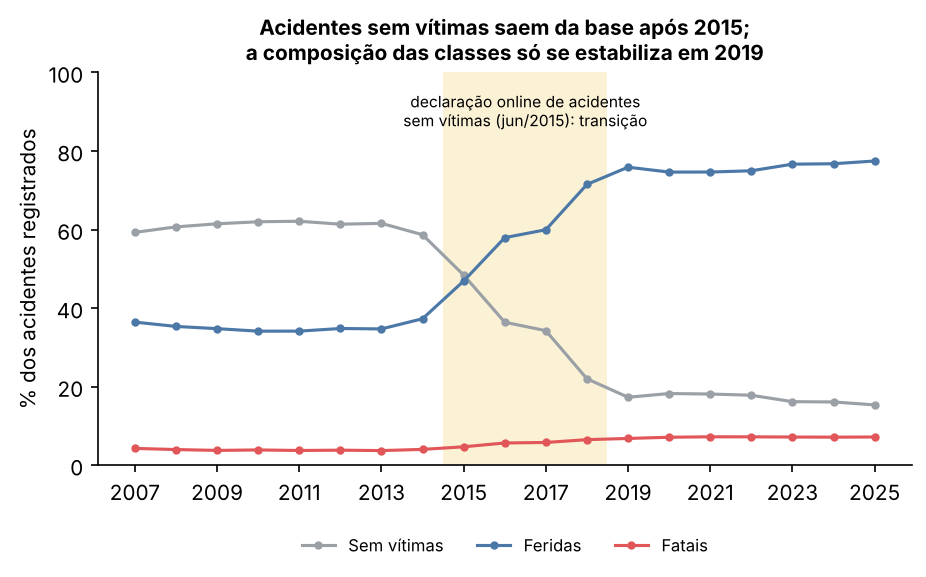

ano,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
total,127675.0,141043.0,158646.0,183469.0,192326.0,184568.0,186748.0,169201.0,122161.0,96363.0,89563.0,69295.0,67446.0,63548.0,64515.0,64606.0,67766.0,73156.0,72529.0
pct_sem_vitimas,59.1,60.4,61.2,61.7,61.7,60.9,61.1,58.1,47.8,35.8,34.3,22.0,17.3,18.2,18.1,17.8,16.2,16.1,15.4


In [3]:
display(Image(str(config.FIGURES_DIR / "eda_01_classes_por_ano.png")))
saidas["historico"][["ano", "total", "pct_sem_vitimas"]].set_index("ano").T

In [4]:
dist = eda.groupby("ano")[config.TARGET].value_counts(normalize=True).unstack().mul(100).round(1)
dist.columns = config.CLASSES_CURTAS
dist

,Sem vítimas,Feridas,Fatais
ano,,,
2017,34.3,60.0,5.8
2018,22.0,71.5,6.5
2019,17.3,75.9,6.8
2020,18.2,74.6,7.1
2021,18.1,74.7,7.2
2022,17.8,75.0,7.2
2023,16.2,76.7,7.2
2024,16.1,76.8,7.1


## 2. Gravidade por tipo de acidente

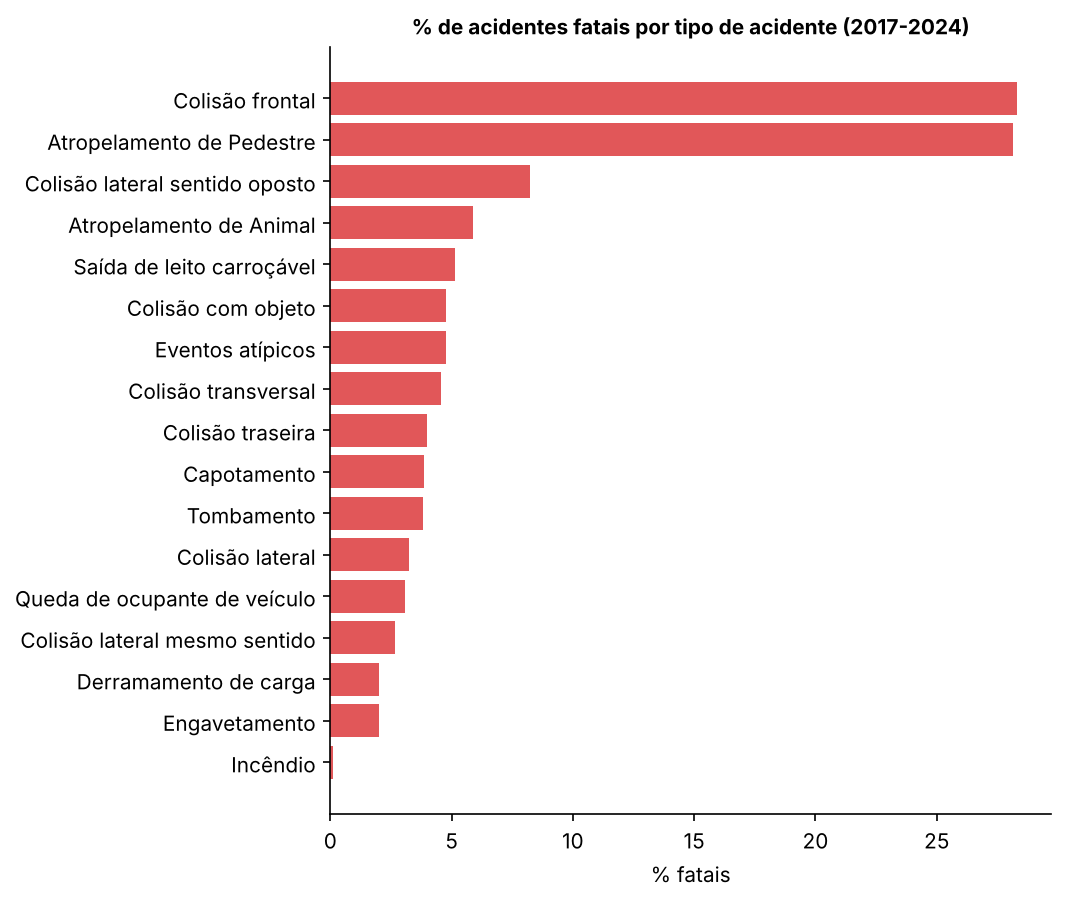

,n,pct_fatais
tipo_acidente,,
Colisão frontal,36700,28.3
Atropelamento de Pedestre,25475,28.2
Colisão lateral sentido oposto,7436,8.2
Atropelamento de Animal,10106,5.9
Saída de leito carroçável,89985,5.1
Colisão com objeto,42999,4.8
Eventos atípicos,2203,4.8
Colisão transversal,69305,4.6
Colisão traseira,104942,4.0


In [5]:
display(Image(str(config.FIGURES_DIR / "eda_02_fatais_por_tipo.png")))
saidas["por_tipo"].round(1)

Colisões frontais e atropelamentos de pedestre têm letalidade várias vezes maior que colisões traseiras. É a associação mais forte da base (ver V de Cramér abaixo). Associação não é causalidade: o tipo de acidente descreve a dinâmica, não a sua origem.

## 3. Hora do dia, tipo de pista e outras condições

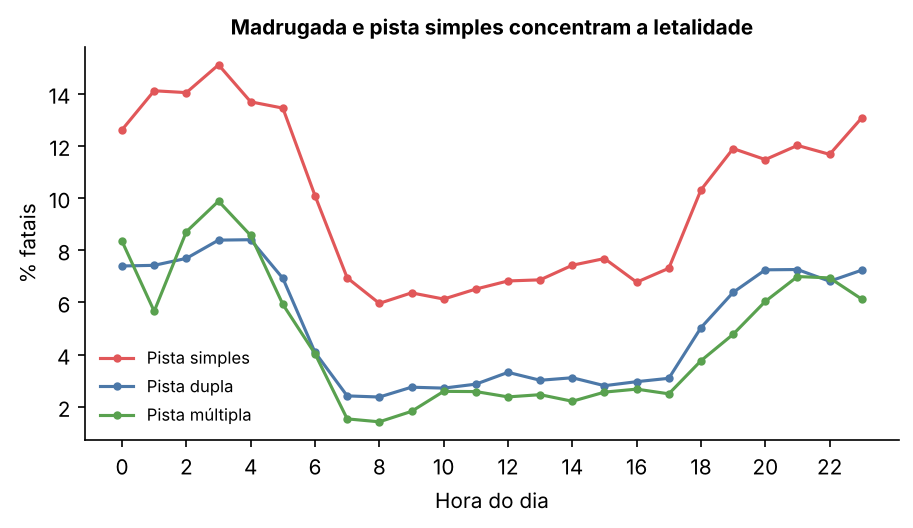

n  pct_fatais
variavel       categoria                             
condicao_meteo Chuva              63930.0         5.8
               Céu Claro         331219.0         7.2
               Garoa/Chuvisco     19565.0         5.6
               Nevoeiro/Neblina    4712.0        11.4
               Nublado            93339.0         6.7
               Outros                30.0         3.3
               Sol                38130.0         5.1
               Vento               1115.0         7.6
dia_semana     domingo            92583.0         8.4
               quarta-feira       70211.0         6.0
               quinta-feira       72948.0         6.3
               segunda-feira      76169.0         6.4
               sexta-feira        86425.0         6.4
               sábado             92728.0         7.6
               terça-feira        68828.0         6.0
faixa_horaria  madrugada          71372.0        10.6
               manha             155732.0         4.7
               noite             161115.0         9.0
               tarde             171673.0         5.1
fase_dia       Amanhecer          27357.0        10.0
               Anoitecer          30722.0         6.4
               Plena Noite       195084.0         9.7
               Pleno dia         306729.0         4.8
regiao         Centro-Oeste       68105.0         7.0
               Nordeste          119692.0        10.2
               Norte              31292.0         9.3
               Sudeste           172165.0         5.7
               Sul               168638.0         5.1
tipo_pista     Dupla             232198.0         4.5
               Múltipla           46883.0         3.8
               Simples           280811.0         9.2
uso_solo       Não               317163.0         8.6
               Sim               242729.0         4.4

In [6]:
display(Image(str(config.FIGURES_DIR / "eda_03_fatais_hora_pista.png")))
t = saidas["taxas_contexto"]
t.pivot_table(index=["variavel", "categoria"], values=["n", "pct_fatais"]).round(1)

Leituras importantes:

- **Pista simples** e **madrugada/noite** concentram a letalidade.
- **Uso do solo = "Não"** (área não urbana, pela leitura do dicionário) tem cerca do dobro de letalidade de "Sim".
- **Chuva tem letalidade menor que céu claro.** Uma explicação plausível é que a chuva aumenta acidentes leves e reduz a velocidade. Esse é um exemplo de por que taxas descritivas não devem ser lidas como efeito causal.

## 4. Associação de cada variável com a gravidade (V de Cramér)

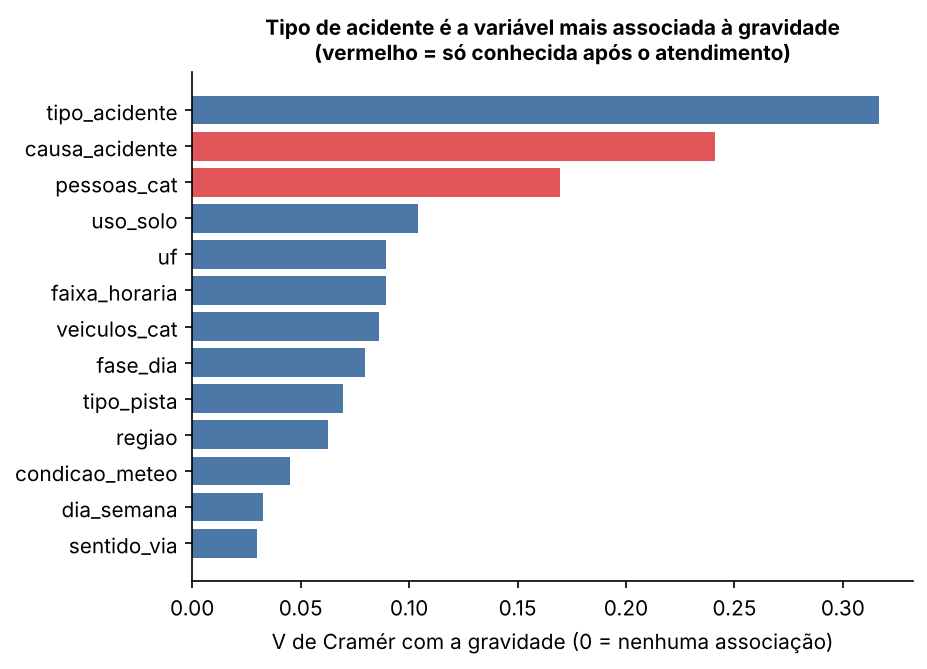

,V de Cramér
tipo_acidente,0.316
causa_acidente,0.241
pessoas_cat,0.170
uso_solo,0.104
uf,0.089
faixa_horaria,0.089
veiculos_cat,0.086
fase_dia,0.079
tipo_pista,0.069
regiao,0.063


In [7]:
display(Image(str(config.FIGURES_DIR / "eda_04_cramers_v.png")))
saidas["cramers_v"].round(3).to_frame("V de Cramér")

`causa_acidente` e `pessoas` (em vermelho) estão entre as mais associadas, mas **só são conhecidas depois do atendimento**: a causa é presumida pelo policial após o levantamento, e o número de pessoas é contado no local e cresce junto com o número de vítimas. Por isso ficam fora do cenário principal (A) e só aparecem nos cenários C e de sensibilidade.

## 5. Distribuição geográfica

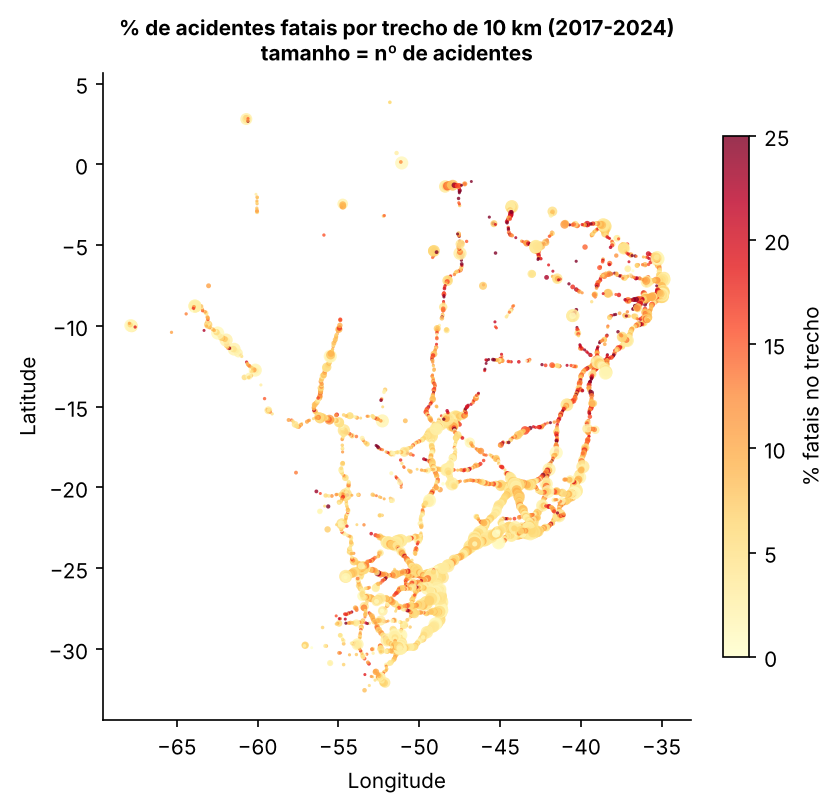

,n,pct_fatais
categoria,,
Centro-Oeste,68105,7.0
Nordeste,119692,10.2
Norte,31292,9.3
Sudeste,172165,5.7
Sul,168638,5.1


In [8]:
display(Image(str(config.FIGURES_DIR / "eda_05_mapa_trechos.png")))
r = t[t.variavel == "regiao"].set_index("categoria")[["n", "pct_fatais"]].round(1)
r

## 6. Qualidade dos dados

- Ausentes explícitos são poucos (clima "Ignorado" ~1,4%; coordenadas fora do Brasil: dezenas de casos).
- `tracado_via` muda de padrão: até 2021 há "Não Informado" (~11% dos registros); "Aclive", "Declive" e "Em Obras" só existem a partir de 2022 e por isso **não** viram variáveis.
- `tipo_acidente` teve categorias renomeadas ou divididas ao longo do tempo (harmonização em `data_processing.MAPA_TIPO_ACIDENTE`).
- `pessoas` difere da soma ilesos + feridos + mortos + ignorados em parte dos registros (contado no log de limpeza).

In [9]:
print(json.loads((config.TABLES_DIR / "log_limpeza.json").read_text()))
eda[["condicao_meteo", "sentido_via", "latitude", "km"]].isna().mean().mul(100).round(2).to_frame("% ausente")

{'linhas_lidas': 632424, 'sem_alvo_valido': 4, 'duplicatas_id': 0, 'data_ou_hora_invalida': 0, 'coordenadas_fora_do_brasil': 54, 'pessoas_diferente_da_soma': 15902, 'linhas_finais': 632420}


,% ausente
condicao_meteo,1.40
sentido_via,0.22
latitude,0.01
km,0.12
